In [6]:
import sys
from pathlib import Path
import numpy as np
import yaml
import jax
import gc
from tqdm.notebook import tqdm
from dataclasses import replace
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection

ROOT = Path("/home/kzeleznikar/IJS-F1/Koda")
CFG = ROOT / "EI_cutoff" / "config" / "config_ibz.yaml"

# Ensure the root folder is in Python's search path
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import EI.ei_unified as eu
from EI_baths.phase_map_plots import plot_maps, scan_maps
from EI_baths.fixed_baths import (
    plot_bz,
    plot_dispersion,
    plot_energy,
    plot_xi,
    solve_state,
    solve_teff,
)
from utils.cosmetics import apply_plt_style
from utils.logger import logger
from utils.plotting_utils import Plotter
import EI.ei_unified as eu
import EI.ei_jax_2 as ej
import EI.ei_phonon as pb
from EI.ei_anderson import solve_anderson

from utils.logger import logger, tqdm_bar
from utils.plotting_utils import Plotter, plot_cmap, format_ax, add_legend, plot_cmap, plot_phase_diag, color_map
from EI_baths.fixed_baths import k_path, take_path, color_line, solve_state, plot_dispersion


apply_plt_style()
pt = Plotter(show=True, close=False)

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", dpi=300)
from utils.cosmetics import SET1_LIST

FIG_PATH = "/home/kzeleznikar/IJS-F1/Notes/latex/figures/"

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from EI_refactor.EI_ness import model as M, baths as B
from EI_refactor.EI_ness import gpu as S  # or gpu

md = M.Model(gap=4.0, ta=1.0, tb=-1.0, v=4.1) 
g = M.sgrid(400)
e0 = M.solve_eq(md, g, 0.0, d=1.0)
tc = M.critical_temperature(md, g)
print(f"Delta_0 = {e0.d}, m_0 = {e0.m:.6f}, T_c = {tc * 0.1 * 11600:.6f} K")

Delta_0 = 0.08388701916375912, m_0 = -0.995702, T_c = 56.750517 K


In [ ]:
r1, r2, A = 0.3, 1.1, 1.0e0 # T1 / Tc (photons), T2 / Tc (phonons), photon amplitude scale
t1, t2 = r1 * tc, r2 * tc
bs = [B.Cavity(t1, w0=0.1, gam=0.01, amp=A * 4 * B.ALPHA * 0.1),
      B.Chord(t2, cs=0.026, gam=0.001, amp=4.2e-6, tpa=1.0, tpb=-1.0)]
pk = B.pack(bs, md, g)
eq = M.solve_eq(md, g, t2, d=e0.d, m=e0.m)  # start: equilibrium at the phonon temperature

In [21]:
s = S.solve(md, g, pk, d=eq.d, m=eq.m)
print(f"Delta / Delta_0 = {s.d / e0.d:.6f}, m = {s.m:.6f}, err = {s.err:.1e}, ok = {s.ok}")

Delta / Delta_0 = 0.000000, m = -0.996840, err = 2.8e-14, ok = True


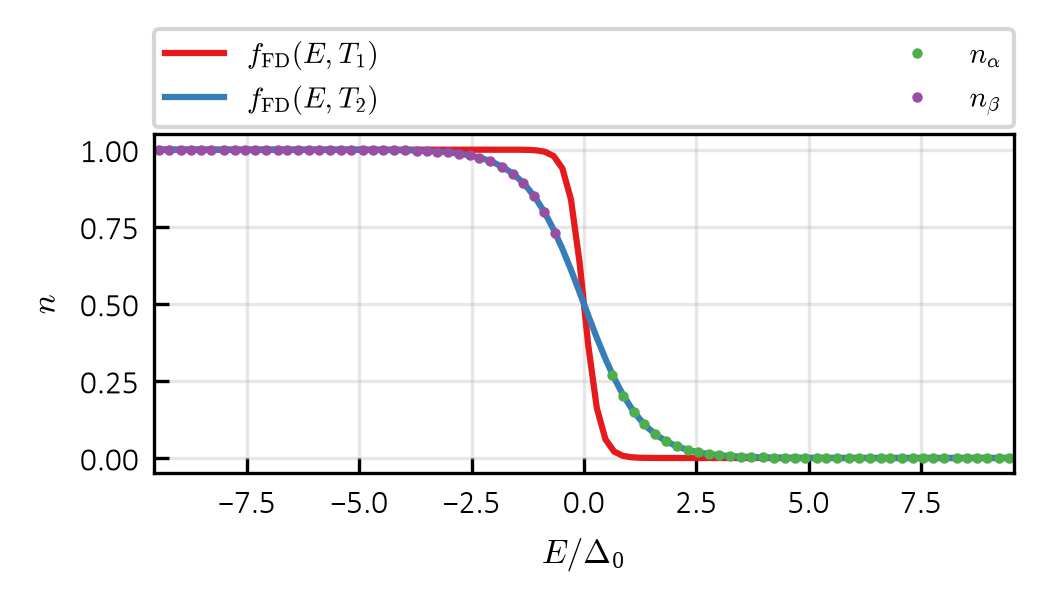

In [22]:
fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))
e = s.st.e / e0.d
ee = np.linspace(e.min(), e.max(), 1000)
for i, (t, lab) in enumerate(((t1, r"$f_{\rm FD}(E, T_1)$"), (t2, r"$f_{\rm FD}(E, T_2)$"))):
    mu = M.fermi(s.st, g.w, md.n, t)[1]
    ax.plot(ee, 1.0 / (1.0 + np.exp((ee * e0.d - mu) / t)), color=SET1_LIST[i], label=lab)
ax.plot(e[0], s.n[0], ".", ms=3, color=SET1_LIST[2], label=r"$n_{\alpha}$")
ax.plot(e[1], s.n[1], ".", ms=3, color=SET1_LIST[3], label=r"$n_{\beta}$")
ax.set_xlim(ee[0] / 10 ,  ee[-1] / 10)
ax.set_xlabel(r"$E/\Delta_0$")
ax.set_ylabel(r"$n$")
ax.grid(alpha=0.3)
ax.tick_params(which="both", direction="in")
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand",
          borderaxespad=0, ncol=2, fontsize=7)
plt.tight_layout()
plt.show()

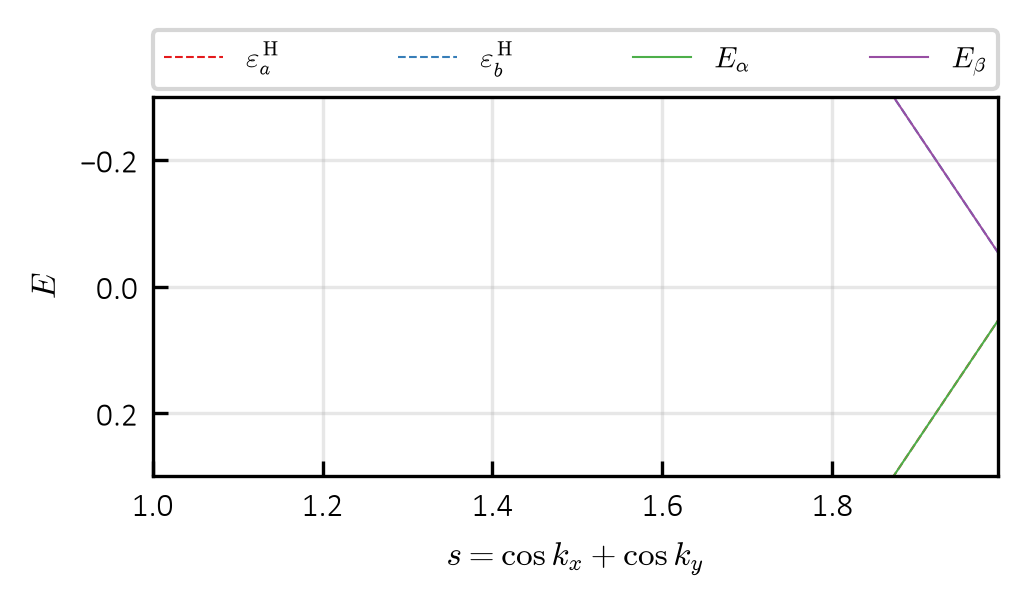

In [23]:
na, nb = 0.5 * (md.n + s.m), 0.5 * (md.n - s.m)
eah = 0.5 * md.gap - 2.0 * md.ta * g.s + md.h * (nb - 0.5)  # Hartree bands, frame of s.st.e
ebh = -0.5 * md.gap - 2.0 * md.tb * g.s + md.h * (na - 0.5)

fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))
ax.plot(g.s, eah, "--", color=SET1_LIST[0], lw = 0.5, label=r"$\varepsilon^{\rm H}_a$")
ax.plot(g.s, ebh, "--", color=SET1_LIST[1], lw = 0.5, label=r"$\varepsilon^{\rm H}_b$")
ax.plot(g.s, s.st.e[0], color=SET1_LIST[2], lw = 0.5, label=r"$E_{\alpha}$")
ax.plot(g.s, s.st.e[1], color=SET1_LIST[3], lw = 0.5, label=r"$E_{\beta}$")
ax.set_xlim(1, g.s[-1])
ax.set_ylim(0.3, -0.3)
ax.set_xlabel(r"$s=\cos k_x+\cos k_y$")
ax.set_ylabel(r"$E$")
ax.grid(alpha=0.3)
ax.tick_params(which="both", direction="in")
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand",
          borderaxespad=0, ncol=4, fontsize=7)
plt.tight_layout()
plt.show()

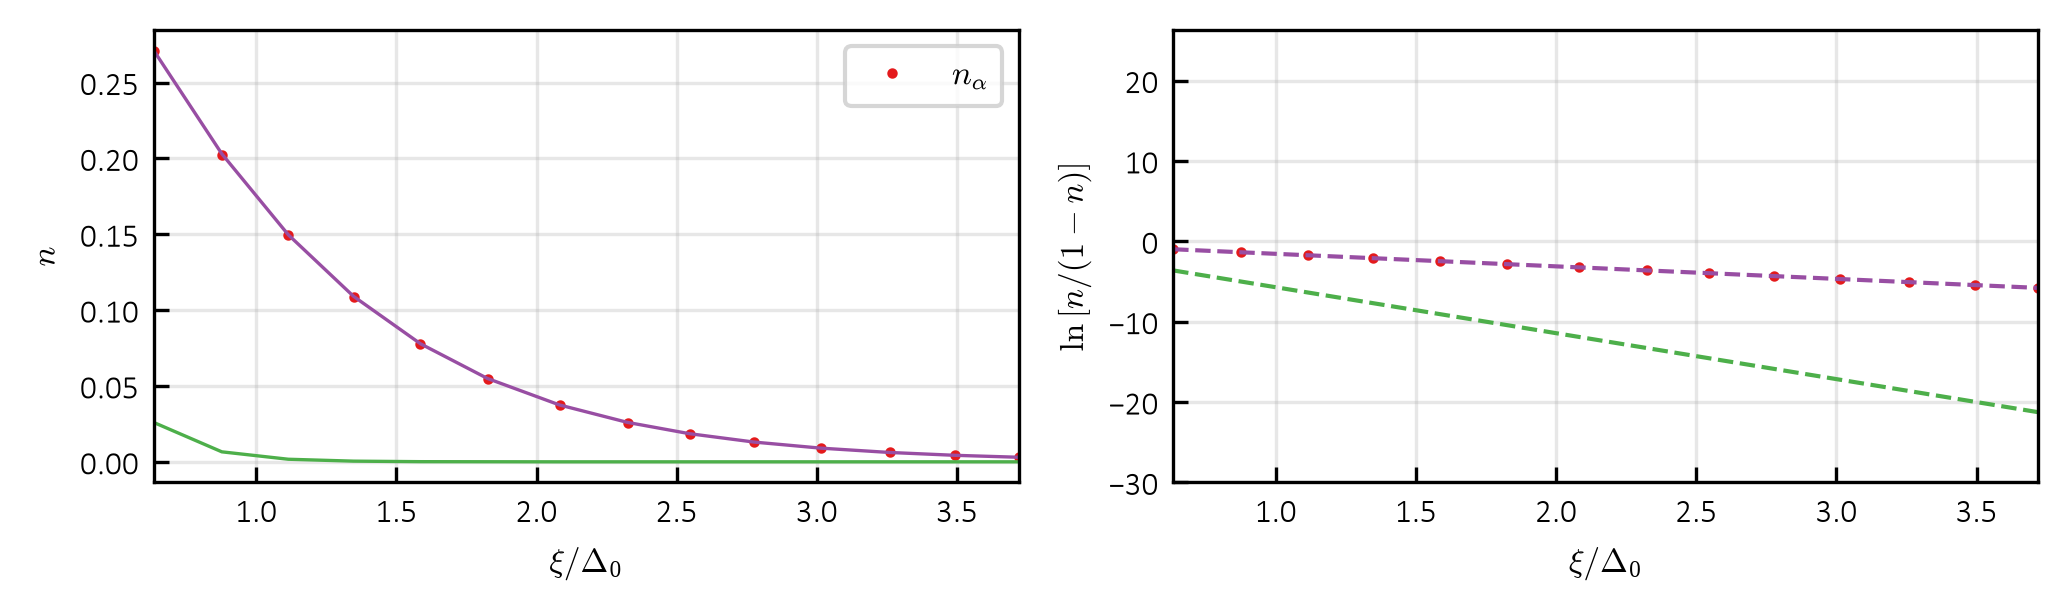

In [24]:
na, nb = 0.5 * (md.n + s.m), 0.5 * (md.n - s.m)
xi = 0.5 * (md.gap - 2.0 * (md.ta - md.tb) * g.s + md.h * (nb - na))  # (eps_a^H - eps_b^H) / 2
x = xi / e0.d

max_val = np.max(s.n[0])
threshold = 0.01 * max_val
valid_mask = s.n[0] >= threshold

x_min = x[valid_mask].min()
x_max = x[valid_mask].max()

ix = np.argsort(x)
lab = r"{\alpha}"
fig, ax = plt.subplots(1, 2, figsize=(2 * 3.47412, 0.6 * 3.47412))
ax[0].plot(x, s.n[0], ".", ms=3, color=SET1_LIST[0], label=rf"$n_{lab}$")
ax[1].plot(x, -s.mu[0], ".", ms=3, color=SET1_LIST[0], label=rf"$n_{lab}$")
for j, (t, lab) in enumerate(((t1, "T_1"), (t2, "T_2"))):
    mu = M.fermi(s.st, g.w, md.n, t)[1]  # alpha solid, beta dashed
    z = (s.st.e[0][ix] - mu) / t
    ax[0].plot(x[ix], 1.0 / (1.0 + np.exp(z)), "-", lw=0.8, color=SET1_LIST[2 + j],
               label=rf"$f_{{\rm FD}}(E,{lab})$" if i == 0 else None)
    ax[1].plot(x[ix], -z, "--", lw=1, color=SET1_LIST[2 + j])
ax[0].set_ylabel(r"$n$")
ax[1].set_ylabel(r"$\ln\left[n/(1-n)\right]$")
for a in ax:
    a.set_xlim(x_min, x_max)
    a.set_xlabel(r"$\xi/\Delta_0$")
    a.grid(alpha=0.3)
    a.tick_params(which="both", direction="in")
ax[1].set_ylim(-30)
ax[0].legend()
plt.tight_layout()
plt.show()

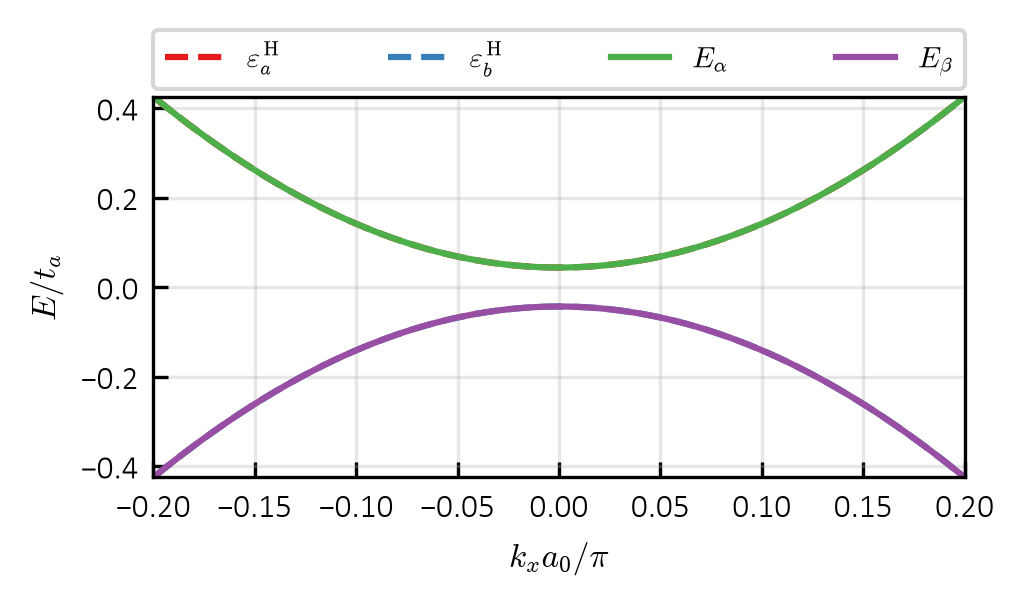

In [25]:
kx = np.linspace(-np.pi / 5, np.pi / 5, 401)
gk = g._replace(s=np.cos(kx) + 1.0)  # k_y = 0
stk = M.mf(md, gk, s.d, s.m)
eak = 0.5 * md.gap - 2.0 * md.ta * gk.s + md.h * (nb - 0.5)
ebk = -0.5 * md.gap - 2.0 * md.tb * gk.s + md.h * (na - 0.5)

fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))
ax.plot(kx / np.pi, eak, "--", color=SET1_LIST[0], label=r"$\varepsilon^{\rm H}_a$")
ax.plot(kx / np.pi, ebk, "--", color=SET1_LIST[1], label=r"$\varepsilon^{\rm H}_b$")
ax.plot(kx / np.pi, stk.e[0], color=SET1_LIST[2], label=r"$E_{\alpha}$")
ax.plot(kx / np.pi, stk.e[1], color=SET1_LIST[3], label=r"$E_{\beta}$")
ax.set_xlim(min(kx / np.pi), max(kx / np.pi))
ax.set_ylim(min(ebk), max(eak))
ax.set_xlabel(r"$k_x a_0 / \pi$")
ax.set_ylabel(r"$E / t_a$")
ax.grid(alpha=0.3)
ax.tick_params(which="both", direction="in")
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand",
          borderaxespad=0, ncol=4, fontsize=7)
plt.tight_layout()
plt.show()